
# Day 7: Hyperparameter Tuning and Model Selection

## Smart Hotel Booking Cancellation Prediction

### Objective
Improve model performance by tuning hyperparameters using group-aware cross-validation.

### Models
- Decision Tree Classifier
- Random Forest Classifier

### Evaluation Metric
F1-score for booking cancellations (class 1).



In [1]:

import pandas as pd  
import joblib # For loading saved preprocessing objects

# Load the training features and target
X_train = pd.read_csv("../data/X_train.csv")
y_train = pd.read_csv("../data/y_train.csv").squeeze("columns")

# Load the preprocessor saved on Day 5
preprocessor = joblib.load("../models/preprocessor.pkl")

print("Training features shape:", X_train.shape)
print("Training target shape:", y_train.shape)
print("Preprocessor loaded successfully!")

Training features shape: (94987, 27)
Training target shape: (94987,)
Preprocessor loaded successfully!


loading only the training data?
During hyperparameter tuning, we use training data only to find the best model settings.

We keep the test dataset separate so that we can evaluate our final model fairly.

#### Setting Up Group-Aware Cross-Validation.

Why are we doing this?
Some bookings in our dataset have identical input features. We don't want identical feature combinations appearing in both the training and validation portions of a fold.

StratifiedGroupKFold helps us:
- Divide the training data into three folds.
- Keep identical feature groups together.
- Try to maintain a similar cancellation/non-cancellation distribution across folds.

In [2]:

from sklearn.model_selection import StratifiedGroupKFold

# Give identical feature combinations the same group ID
train_groups = X_train.groupby(
    X_train.columns.tolist(),
    dropna=False,
    sort=False
).ngroup()

# Create 3-fold group-aware cross-validation
cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Check the number of unique groups
print("Unique training groups:", train_groups.nunique())
print("Cross-validation setup completed!")


Unique training groups: 67876
Cross-validation setup completed!


#### Setting Up Decision Tree Hyperparameter Tuning.


In [3]:

from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# Create a pipeline with preprocessing and Decision Tree
dt_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", DecisionTreeClassifier(random_state=42))
])

# Define hyperparameter values to test
dt_param_grid = {
    "model__max_depth": [5, 10, 15],
    "model__min_samples_split": [2, 10],
    "model__min_samples_leaf": [1, 5]
}

# Create GridSearchCV
dt_grid_search = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=dt_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

print("Decision Tree GridSearchCV setup completed!")


Decision Tree GridSearchCV setup completed!


#### Runnng the GridSearchCV

In [4]:

# Run hyperparameter tuning using training data only
dt_grid_search.fit(
    X_train,
    y_train,
    groups=train_groups  # Keep identical feature groups in the same fold
)

# Display the best hyperparameters
print("Best Parameters:", dt_grid_search.best_params_)

# Display the best cross-validation F1-score
print("Best CV F1-score:", round(dt_grid_search.best_score_, 4))


Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best Parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__min_samples_split': 2}
Best CV F1-score: 0.7695


Decision Tree tuning results
Before tuning
76.91%
CV F1-score

After tuning
76.95%
CV F1-score


The improvement is 0.04 percentage points. It's very small, but the tuned configuration performed slightly better in our search.
Best hyperparameters
Parameter	Best value
max_depth	        10
min_samples_leaf	5
min_samples_split	2

What does this mean?

Our original Decision Tree already had max_depth=10, so the search retained that setting. Increasing min_samples_leaf to 5 gave a small improvement.

This is a useful finding: hyperparameter tuning does not always produce a major improvement.

In [6]:
#SAVING


# Get the best trained Decision Tree pipeline
best_dt_model = dt_grid_search.best_estimator_

# Save the tuned model, including preprocessing
joblib.dump(best_dt_model, "../models/tuned_decision_tree.pkl")

print("Tuned Decision Tree model saved successfully!")


Tuned Decision Tree model saved successfully!


#### Set Up Random Forest Hyperparameter Tuning

Our previous Random Forest cross-validation F1-score was 75.91%.

We'll use RandomizedSearchCV to test different combinations of hyperparameters without trying every possible combination. This is generally faster than GridSearchCV for larger search spaces.


In [7]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

# Create Random Forest pipeline
rf_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

# Define hyperparameters to explore
rf_param_dist = {
    "model__n_estimators": [100, 150],
    "model__max_depth": [10, 15, 20],
    "model__min_samples_split": [2, 10],
    "model__min_samples_leaf": [1, 5]
}

# Set up randomized hyperparameter search
rf_random_search = RandomizedSearchCV(
    estimator=rf_pipeline, #which model should we tune
    param_distributions=rf_param_dist,
    n_iter=8,  # Test 8 random combinations
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=1,  # Avoid excessive memory usage
    verbose=1
)

print("Random Forest RandomizedSearchCV setup completed!")



Random Forest RandomizedSearchCV setup completed!


RandomizedSearchCV is used to find suitable hyperparameters by testing randomly selected combinations. The estimator specifies the model, param_distributions defines the possible hyperparameter values, and n_iter specifies the number of combinations to evaluat

#### Executing RandomizedSearchCV

In [9]:

# Run Random Forest hyperparameter tuning
rf_random_search.fit(
    X_train,
    y_train,
    groups=train_groups  # Keep identical feature groups together
)

# Display the best hyperparameters
print("Best Parameters:", rf_random_search.best_params_)

# Display the best cross-validation F1-score
print("Best CV F1-score:", round(rf_random_search.best_score_, 4))


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters: {'model__n_estimators': 100, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_depth': 20}
Best CV F1-score: 0.7792


#### Updated model comparison
Model	CV F1-score
Logistic Regression	71.32%
Original Decision Tree	76.91%
Tuned Decision Tree	76.95%
Original Random Forest	75.91%
Tuned Random Forest	77.92%

Our tuned Random Forest is now the leading candidate based on the cross-validation results. We'll still need to evaluate the final selected model carefully.

In [10]:
#saving


# Get the best trained Random Forest pipeline
best_rf_model = rf_random_search.best_estimator_

# Save the complete pipeline (preprocessing + Random Forest)
joblib.dump(best_rf_model, "../models/tuned_random_forest.pkl")

print("Tuned Random Forest model saved successfully!")


Tuned Random Forest model saved successfully!


#### comparing the model



In [13]:

# Create a comparison table for the tuned models
tuned_comparison_df = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Best CV F1-score": [
        dt_grid_search.best_score_,
        rf_random_search.best_score_
    ]
})

# Display the comparison
print(tuned_comparison_df.round(4))

# Save the comparison results
tuned_comparison_df.to_csv(
    "../data/tuned_model_comparison.csv",
    index=False
)

print("Tuned model comparison saved successfully!")


           Model  Best CV F1-score
0  Decision Tree            0.7695
1  Random Forest            0.7792
Tuned model comparison saved successfully!


#### Evaluate the selected model on test data

I have used training data and cross-validation to select our model. Now I'll evaluate it on the held-out test dataset to see how well it predicts unseen hotel bookings.

What are we checking?


Accuracy	How many bookings were predicted correctly overall

Precision	Of the bookings predicted to cancel, how many actually canceled

Recall	Of the actual cancellations, how many we successfully identified

F1-score	Balance between precision and recall

For our hotel booking project, recall is particularly important because missing a potential cancellation could affect hotel revenue and room planning.

In [14]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Load the untouched test dataset
X_test = pd.read_csv("../data/X_test.csv")
y_test = pd.read_csv("../data/y_test.csv").squeeze("columns")

# Predict cancellations using the tuned Random Forest
y_pred = best_rf_model.predict(X_test)

# Calculate evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))

# Detailed classification results
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.8522
Precision: 0.8556
Recall: 0.7282
F1-score: 0.7868

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.93      0.89     15147
           1       0.86      0.73      0.79      9074

    accuracy                           0.85     24221
   macro avg       0.85      0.83      0.84     24221
weighted avg       0.85      0.85      0.85     24221



#### Confusion Matrix
Now let's visualize where our model makes correct and incorrect predictions.

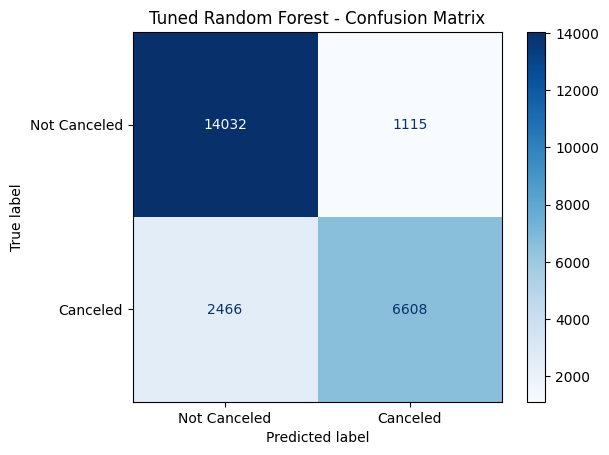

In [15]:

# Import libraries
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not Canceled", "Canceled"],
    cmap="Blues",
    values_format="d"
)

plt.title("Tuned Random Forest - Confusion Matrix")
plt.show()


For my project, False Negatives are particularly important because these are bookings that actually got canceled but our model failed to identify.

TN (14,032): Bookings correctly predicted as not canceled.

FP (1,115): Bookings predicted to cancel but actually not canceled.

FN (2,466): Bookings that actually canceled but the model missed.

TP (6,608): Cancellations correctly identified.

### Final Model Selection

After hyperparameter tuning, Random Forest was selected as the final model because it achieved the highest cross-validation F1-score (77.92%) among the models tested.

The tuned Random Forest achieved the following results on the test dataset:

- Accuracy: 85.22%
- Precision: 85.56%
- Recall: 72.82%
- F1-score: 78.68%

The confusion matrix showed that the model correctly identified 6,608 canceled bookings and 14,032 non-canceled bookings. However, it missed 2,466 actual cancellations.

**Conclusion:** The tuned Random Forest provides a useful balance between identifying cancellations and avoiding false cancellation predictions. Improving recall could be considered in future work.